# Leakage-safe churn model selection and XAI

This notebook is the authoritative modelling workflow. The holdout set is isolated before model selection; every learned preprocessing operation is fitted inside each CV fold.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebook':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.churn_workflow import TARGET, evaluate_holdout, select_model, transformed_frame

df = pd.read_csv(ROOT / 'data' / 'Churn_Modelling.csv')
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
assert set(X_train.index).isdisjoint(X_holdout.index)
print(f'Training: {len(X_train):,}; sealed holdout: {len(X_holdout):,}')

Training: 8,000; sealed holdout: 2,000


## Training-only model selection

`select_model` uses shuffled 5-fold `StratifiedKFold`. Each search receives a complete feature-engineering → preprocessing → classifier pipeline and is refit on F1. Neither holdout object is passed to this function.

In [2]:
final_model, cv_comparison, selection = select_model(X_train, y_train)
display(cv_comparison.drop(columns='best_params').style.format(precision=3))
print('Selected from CV only:', selection['selected_model'])
print('Best parameters:', selection['best_params'])

,model,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std
0,XGBoost,0.850,0.009,0.640,0.019,0.604,0.045,0.621,0.032,0.861,0.012
1,Random Forest,0.847,0.006,0.631,0.013,0.601,0.036,0.615,0.023,0.855,0.013
2,SVM,0.789,0.004,0.488,0.007,0.759,0.037,0.594,0.015,0.849,0.010
3,Logistic Regression,0.720,0.007,0.392,0.009,0.686,0.037,0.499,0.015,0.766,0.018


Selected from CV only: XGBoost
Best parameters: {'classifier__subsample': 0.8, 'classifier__scale_pos_weight': 2.0, 'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.8}


## One-time final holdout evaluation

This is the first use of the holdout labels. These results are reported separately and do not influence model or hyperparameter selection.

accuracy: 0.854
precision: 0.645
recall: 0.624
f1: 0.634
roc_auc: 0.867
              precision    recall  f1-score   support

           0       0.90      0.91      0.91      1593
           1       0.64      0.62      0.63       407

    accuracy                           0.85      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



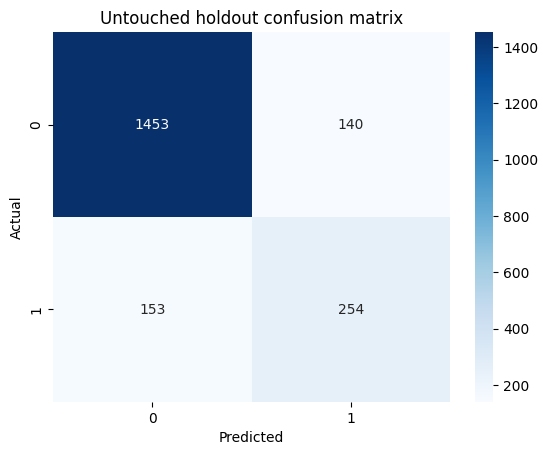

In [3]:
holdout_results = evaluate_holdout(final_model, X_holdout, y_holdout)
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    print(f'{metric}: {holdout_results[metric]:.3f}')

holdout_predictions = final_model.predict(X_holdout)
print(classification_report(y_holdout, holdout_predictions))
sns.heatmap(confusion_matrix(y_holdout, holdout_predictions), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Untouched holdout confusion matrix');

## SHAP explanations with encoded feature names

SHAP is run only after selection. Raw holdout rows are transformed through the already-fitted winning pipeline. Column labels come directly from the fitted `ColumnTransformer`, preserving the mapping after scaling and one-hot encoding.

c:\Users\tuyet\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


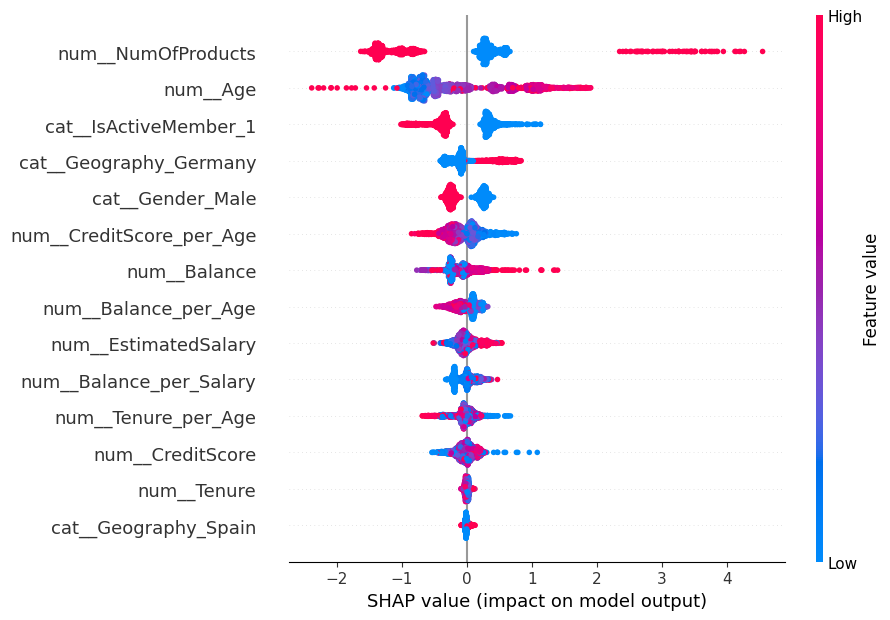

In [4]:
import shap

X_holdout_transformed = transformed_frame(final_model, X_holdout)
classifier = final_model.named_steps['classifier']
explainer = shap.TreeExplainer(classifier)
shap_values = explainer(X_holdout_transformed)
# Binary XGBoost returns a 2-D explanation; some classifiers return a class dimension.
values_for_churn = shap_values[:, :, 1] if shap_values.values.ndim == 3 else shap_values
shap.plots.beeswarm(values_for_churn, max_display=15)

## Power BI export

Only the untouched holdout receives final predictions, keeping the dashboard extract aligned with the reported generalisation evaluation.

In [5]:
results_df = df.loc[X_holdout.index].copy()
results_df['Predicted_Churn'] = holdout_predictions
results_df['Churn_Risk_Percentage'] = final_model.predict_proba(X_holdout)[:, 1]
output_path = ROOT / 'reports' / 'bank_churn_predictions.csv'
output_path.parent.mkdir(exist_ok=True)
results_df.to_csv(output_path, index=False)
print(f'Exported {len(results_df):,} rows to {output_path}')

Exported 2,000 rows to C:\TUYET\GIT_REPO\End-to-End-Churn-Prediction-PowerBI-XAI\reports\bank_churn_predictions.csv


## Optional DiCE counterfactual analysis

DiCE's reference data is restricted to the training partition. This avoids using holdout labels or holdout-derived ranges when constructing explanations. Counterfactuals are generated only after final evaluation and cannot affect model selection.

In [6]:
import dice_ml
from src.churn_workflow import CATEGORICAL_FEATURES, ID_COLUMNS, EXCLUDED_FEATURES, NUMERIC_FEATURES

training_for_dice = X_train.copy()
training_for_dice[TARGET] = y_train
training_for_dice = final_model.named_steps['feature_engineering'].transform(training_for_dice)
dice_data = dice_ml.Data(
    dataframe=training_for_dice, continuous_features=NUMERIC_FEATURES, outcome_name=TARGET
)
dice_model = dice_ml.Model(model=final_model, backend='sklearn')
dice_explainer = dice_ml.Dice(dice_data, dice_model, method='random')
high_risk_raw = X_holdout.loc[final_model.predict_proba(X_holdout)[:, 1] >= 0.5].head(1)
high_risk = final_model.named_steps['feature_engineering'].transform(high_risk_raw)
dice_results = dice_explainer.generate_counterfactuals(
    high_risk, total_CFs=3, desired_class='opposite',
    features_to_vary=['NumOfProducts', 'IsActiveMember', 'CreditScore']
)
dice_results.visualize_as_dataframe(show_only_changes=True)

  0%|          | 0/1 [00:00<?, ?it/s]c:\Users\tuyet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\tuyet\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
100%|██████████| 1/1 [00:00<00:00,  7.40it/s]

Query instance (original outcome : 1)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,IsActiveMember,EstimatedSalary,Balance_per_Age,Balance_per_Salary,Tenure_per_Age,CreditScore_per_Age,Exited
0,505,France,Male,49,7,80001.226562,1,0,135180.109375,1600.024658,0.591808,0.14,10.1,1



Diverse Counterfactual set (new outcome: 0)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,IsActiveMember,EstimatedSalary,Balance_per_Age,Balance_per_Salary,Tenure_per_Age,CreditScore_per_Age,Exited
0,609,-,-,-,-,-,2,-,-,-,-,-,-,0
1,676,-,-,-,-,-,2,-,-,-,-,-,-,0
2,610,-,-,-,-,-,2,-,-,-,-,-,-,0
